# EDA: Electricity Consumption Behaviour in Student Hostels

**Based on the conference paper:** *Exploratory Analysis of Electricity Consumption Behaviour in Student Hostels*.

**Problem statement:** Electricity usage in student hostels varies according to occupancy, academic schedules, weather, holidays, and individual usage habits. Institutions often have only aggregate consumption information, making it difficult to understand unusual usage patterns, periods of excessive consumption, and variations between hostel blocks.

**Reference dataset:** Pandey et al. (2025), *Scientific Data*, 12, 798. DOI: 10.1038/s41597-025-05166-7.

> Important: the source article describes the dataset and says raw datasets are available upon request. Upload the actual dorm CSV file(s) before running this notebook. This notebook will calculate results from the supplied data; it does not contain invented results. The dataset is from monitored residential dormitories and does not automatically contain academic timetable, holiday, resident-count, or hostel-block fields.


## 1. Import libraries and upload the CSV

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

# Google Colab: upload one CSV. For local use, set FILE_PATH manually.
try:
    from google.colab import files
    uploaded = files.upload()
    csv_files = [name for name in uploaded if name.lower().endswith(".csv")]
    if not csv_files:
        raise ValueError("Upload at least one CSV file.")
    FILE_PATH = csv_files[0]
except ImportError:
    FILE_PATH = "your_dormitory_data.csv"  # Replace with your CSV path.

df = pd.read_csv(FILE_PATH)
print("Dataset shape:", df.shape)
display(df.head())
display(df.info())


Saving Synthetic_Hostel_Electricity_Dataset.csv to Synthetic_Hostel_Electricity_Dataset (1).csv
Dataset shape: (4320, 11)


,timestamp,hostel_block,occupancy_estimate,academic_day,holiday,outdoor_temperature_C,outdoor_relative_humidity_pct,hvac_energy_kWh,lighting_energy_kWh,plug_load_energy_kWh,total_energy_kWh
0,2026-01-01 00:00:00,Block A,100.0,True,False,23.962502,69.230078,2.929198,1.365876,1.065608,5.383692
1,2026-01-01 00:00:00,Block B,82.0,True,False,23.962502,69.230078,2.486120,1.461635,1.377292,5.465049
2,2026-01-01 00:00:00,Block C,110.0,True,False,23.962502,69.230078,3.054534,1.676101,1.190327,5.987338
3,2026-01-01 01:00:00,Block A,55.0,True,False,21.793861,80.557163,2.265298,1.428288,1.317557,4.983329
4,2026-01-01 01:00:00,Block B,46.0,True,False,21.793861,80.557163,2.152753,1.555877,1.122780,4.905702


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4320 entries, 0 to 4319
Data columns (total 11 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   timestamp                      4320 non-null   object 
 1   hostel_block                   4320 non-null   object 
 2   occupancy_estimate             4286 non-null   float64
 3   academic_day                   4320 non-null   bool   
 4   holiday                        4320 non-null   bool   
 5   outdoor_temperature_C          4269 non-null   float64
 6   outdoor_relative_humidity_pct  4320 non-null   float64
 7   hvac_energy_kWh                4320 non-null   float64
 8   lighting_energy_kWh            4320 non-null   float64
 9   plug_load_energy_kWh           4320 non-null   float64
 10  total_energy_kWh               4295 non-null   float64
dtypes: bool(2), float64(7), object(2)
memory usage: 312.3+ KB


None

## 2. Inspect columns and identify source variables

In [ ]:
print("Columns:")
for c in df.columns:
    print(c)

display(df.describe(include="all").T)

# Exact source variable names documented in Pandey et al. (2025)
known_energy = ["Overall_Energy_usage_KWh", "HVAC_Energy_usage_KWh"]
known_context = [
    "Indoor_Temperature_C", "Indoor_RH_Percent", "Illumination_LUX",
    "Indoor_CO2_PPM", "Indoor_TVOC_PPB", "Outdoor_Temp_C",
    "Outdoor_RH_Percent", "Dewpoint_Temp_C", "Wind_Speed",
    "Wind_Direction", "Solar_Radiation_DNI_W_m2",
    "X1_hr_Precipitation_m"
]
print("Documented energy fields present:", [c for c in known_energy if c in df.columns])
print("Documented context fields present:", [c for c in known_context if c in df.columns])


Columns:
timestamp
hostel_block
occupancy_estimate
academic_day
holiday
outdoor_temperature_C
outdoor_relative_humidity_pct
hvac_energy_kWh
lighting_energy_kWh
plug_load_energy_kWh
total_energy_kWh


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
timestamp,4320,1440,2026-01-01 00:00:00,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hostel_block,4320,3,Block A,1440,NaN,NaN,NaN,NaN,NaN,NaN,NaN
occupancy_estimate,4286.0,NaN,NaN,NaN,74.54783,21.194789,10.0,60.0,76.0,90.0,125.0
academic_day,4320,2,True,4176,NaN,NaN,NaN,NaN,NaN,NaN,NaN
holiday,4320,2,False,4176,NaN,NaN,NaN,NaN,NaN,NaN,NaN
outdoor_temperature_C,4269.0,NaN,NaN,NaN,27.057606,3.130842,19.528808,24.456132,27.021705,29.673239,34.22955
outdoor_relative_humidity_pct,4320.0,NaN,NaN,NaN,72.24301,5.70941,52.193514,68.355144,72.299492,76.059657,89.419858
hvac_energy_kWh,4320.0,NaN,NaN,NaN,2.746066,0.457106,0.932951,2.433492,2.745423,3.061857,4.146188
lighting_energy_kWh,4320.0,NaN,NaN,NaN,1.250058,0.348016,0.44419,0.912325,1.359473,1.558556,1.938435
plug_load_energy_kWh,4320.0,NaN,NaN,NaN,1.287834,0.287647,0.403839,1.080663,1.251848,1.479438,2.308259


Documented energy fields present: []
Documented context fields present: []


## 3. Data quality: missing values, duplicates, and data types

,Missing_Count,Missing_Percent
outdoor_temperature_C,51,1.18
occupancy_estimate,34,0.79
total_energy_kWh,25,0.58
hostel_block,0,0.00
timestamp,0,0.00
holiday,0,0.00
academic_day,0,0.00
outdoor_relative_humidity_pct,0,0.00
hvac_energy_kWh,0,0.00
lighting_energy_kWh,0,0.00


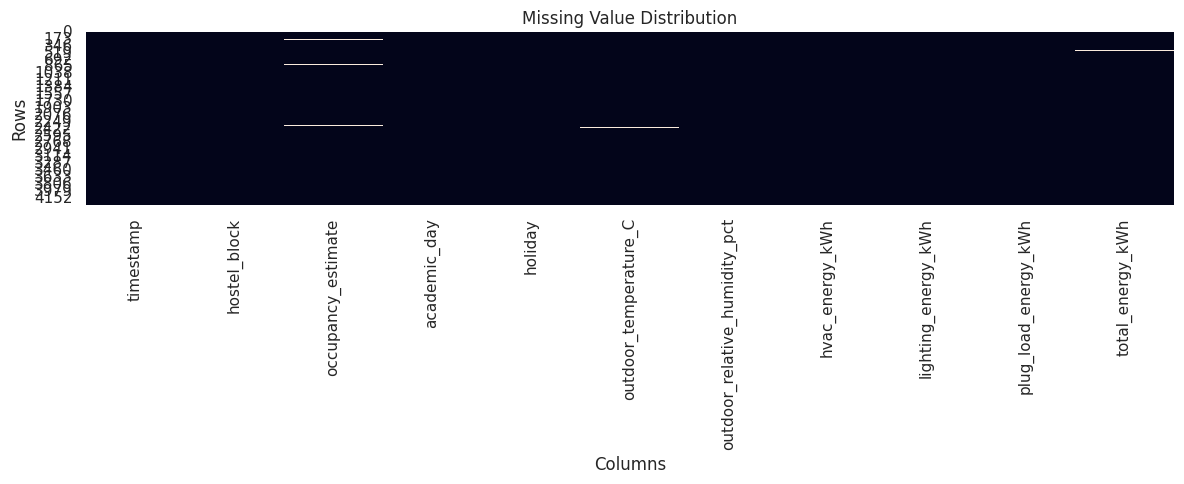

Exact duplicate rows: 0
Data types:


,Data_Type
timestamp,object
hostel_block,object
occupancy_estimate,float64
academic_day,bool
holiday,bool
outdoor_temperature_C,float64
outdoor_relative_humidity_pct,float64
hvac_energy_kWh,float64
lighting_energy_kWh,float64
plug_load_energy_kWh,float64


In [ ]:
missing = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percent": (df.isna().mean() * 100).round(2)
}).sort_values("Missing_Percent", ascending=False)
display(missing)

plt.figure(figsize=(12, 5))
sns.heatmap(df.isna(), cbar=False)
plt.title("Missing Value Distribution")
plt.xlabel("Columns"); plt.ylabel("Rows")
plt.tight_layout(); plt.show()

print("Exact duplicate rows:", df.duplicated().sum())
print("Data types:")
display(df.dtypes.to_frame("Data_Type"))


## 4. Parse timestamp and select a valid energy measure

In [ ]:
# The source describes timestamps in yyyy-mm-dd hh:mm format.
time_candidates = [c for c in df.columns if c.lower() in ["timestamp", "datetime", "date_time", "date"]]
if not time_candidates:
    time_candidates = [c for c in df.columns if "time" in c.lower() or "date" in c.lower()]
TIME_COL = time_candidates[0] if time_candidates else None

if TIME_COL:
    df[TIME_COL] = pd.to_datetime(df[TIME_COL], errors="coerce")
    df = df.dropna(subset=[TIME_COL]).sort_values(TIME_COL).copy()
    df["Hour"] = df[TIME_COL].dt.hour
    df["Date"] = df[TIME_COL].dt.date
    df["DayOfWeek"] = df[TIME_COL].dt.day_name()
    df["Month"] = df[TIME_COL].dt.to_period("M").astype(str)
    print("Timestamp column:", TIME_COL)
else:
    print("No timestamp column detected. Temporal analysis will be skipped.")

# Prefer the source's whole-building total; analyse HVAC separately.
ENERGY_COL = "Overall_Energy_usage_KWh" if "Overall_Energy_usage_KWh" in df.columns else None
if ENERGY_COL is None and "HVAC_Energy_usage_KWh" in df.columns:
    ENERGY_COL = "HVAC_Energy_usage_KWh"
    print("Overall total unavailable; using HVAC energy as a limited proxy.")
if ENERGY_COL:
    df[ENERGY_COL] = pd.to_numeric(df[ENERGY_COL], errors="coerce")
    print("Primary energy field:", ENERGY_COL)
    display(df[ENERGY_COL].describe())
else:
    print("No documented overall/HVAC energy field found. Inspect columns and set ENERGY_COL manually.")


Timestamp column: timestamp
No documented overall/HVAC energy field found. Inspect columns and set ENERGY_COL manually.


## 5. Overall energy distribution

In [ ]:
if ENERGY_COL:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    sns.histplot(df[ENERGY_COL].dropna(), kde=True, ax=axes[0])
    axes[0].set_title("Energy Consumption Distribution")
    axes[0].set_xlabel("Energy (kWh, as documented)")
    sns.boxplot(x=df[ENERGY_COL], ax=axes[1])
    axes[1].set_title("Energy Consumption Boxplot")
    plt.tight_layout(); plt.show()
    print("Valid observations:", df[ENERGY_COL].count())
    print("Mean:", df[ENERGY_COL].mean())
    print("Median:", df[ENERGY_COL].median())
    print("Minimum:", df[ENERGY_COL].min())
    print("Maximum:", df[ENERGY_COL].max())
else:
    print("Skipped: no selected energy field.")


Skipped: no selected energy field.


## 6. Hourly, daily, weekday, and monthly patterns

In [ ]:
if ENERGY_COL and TIME_COL:
    hourly = df.groupby("Hour")[ENERGY_COL].mean()
    hourly.plot(figsize=(10, 4), marker="o")
    plt.title("Average Energy by Hour")
    plt.xlabel("Hour of day"); plt.ylabel("Mean energy (kWh)")
    plt.xticks(range(24)); plt.tight_layout(); plt.show()

    # Minute-level interval energy can be summed to daily totals.
    daily = df.groupby("Date")[ENERGY_COL].sum(min_count=1)
    daily.plot(figsize=(13, 4))
    plt.title("Daily Sum of Recorded Energy")
    plt.xlabel("Date"); plt.ylabel("Daily sum (kWh)")
    plt.tight_layout(); plt.show()

    order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
    plt.figure(figsize=(10, 4))
    sns.boxplot(data=df, x="DayOfWeek", y=ENERGY_COL, order=order)
    plt.title("Energy Distribution by Weekday")
    plt.xticks(rotation=30); plt.tight_layout(); plt.show()

    monthly = df.groupby("Month")[ENERGY_COL].mean()
    monthly.plot(figsize=(12, 4), marker="o")
    plt.title("Monthly Average Recorded Energy")
    plt.xlabel("Month"); plt.ylabel("Mean energy (kWh)")
    plt.xticks(rotation=45); plt.tight_layout(); plt.show()
else:
    print("Skipped: timestamp or energy variable unavailable.")


Skipped: timestamp or energy variable unavailable.


## 7. Indoor/outdoor environment versus energy

In [ ]:
context_cols = [c for c in known_context if c in df.columns]
for c in context_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")
    plot = df[[c, ENERGY_COL]].dropna() if ENERGY_COL else pd.DataFrame()
    if len(plot) > 1:
        plt.figure(figsize=(6, 4))
        sns.scatterplot(data=plot, x=c, y=ENERGY_COL, alpha=0.25, s=12)
        plt.title(f"{c} vs {ENERGY_COL}")
        plt.tight_layout(); plt.show()
        print(c, "correlation:", plot.corr(numeric_only=True).iloc[0,1])
if not context_cols:
    print("No documented context variables found in this CSV.")


No documented context variables found in this CSV.


## 8. Occupant behaviour: window/door state

In [ ]:
# Source describes window/door state fields as binary 0/1.
state_cols = [c for c in df.columns if ("window" in c.lower() or "door" in c.lower())]
print("Possible window/door state fields:", state_cols)
for c in state_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")
    if ENERGY_COL:
        summary = df.groupby(c)[ENERGY_COL].agg(["count","mean","median"])
        print("\\n", c)
        display(summary)
        sns.boxplot(data=df, x=c, y=ENERGY_COL)
        plt.title(f"{ENERGY_COL} by {c} state (verify 0/1 labels)")
        plt.tight_layout(); plt.show()


Possible window/door state fields: ['outdoor_temperature_C', 'outdoor_relative_humidity_pct']


## 9. Outlier detection using IQR

In [ ]:
if ENERGY_COL:
    vals = df[ENERGY_COL].dropna()
    q1, q3 = vals.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5*iqr, q3 + 1.5*iqr
    outliers = df[(df[ENERGY_COL] < low) | (df[ENERGY_COL] > high)]
    print("Lower bound:", low, "Upper bound:", high)
    print("Potential outlier rows:", len(outliers))
    display(outliers.head(25))
    plt.figure(figsize=(13,4))
    plt.plot(df.index, df[ENERGY_COL], alpha=.65, label="Energy")
    plt.scatter(outliers.index, outliers[ENERGY_COL], s=14, label="Potential outliers")
    plt.title("Potential Unusual Energy Readings")
    plt.xlabel("Row index"); plt.ylabel("Energy (kWh)")
    plt.legend(); plt.tight_layout(); plt.show()


## 10. Correlation heatmap

In [ ]:
numeric_cols = [c for c in (context_cols + ([ENERGY_COL] if ENERGY_COL else [])) if c in df.columns]
numeric = df[numeric_cols].select_dtypes(include=np.number)
if numeric.shape[1] >= 2:
    plt.figure(figsize=(11,8))
    sns.heatmap(numeric.corr(), annot=True, cmap="coolwarm", fmt=".2f")
    plt.title("Correlation Among Energy and Available Context Variables")
    plt.tight_layout(); plt.show()
else:
    print("Not enough numeric energy/context variables for correlation analysis.")


Not enough numeric energy/context variables for correlation analysis.


## 11. Limitations and final interpretation

Use the actual outputs to write findings. Do not fill in results before running the notebook.

- **Occupancy:** the referenced dataset describes window/door behaviour, but a resident headcount may not be present. Do not treat window state as occupancy.
- **Academic schedule and holidays:** require an external academic calendar or labelled schedule dataset if absent.
- **Hostel blocks:** compare only when multiple dorm identifiers and comparable files are available. A single monitored dorm is not a multi-block comparison.
- **Weather:** outdoor sensor fields are documented; distinguish them from indoor temperature and humidity.
- **Outliers:** investigate flagged readings with neighbouring timestamps and sensor context; do not automatically delete them.
- **Retrofit comparison:** compare matched pre/post periods and analyse HVAC separately. The 77.81% HVAC reduction is reported by Pandey et al. (2025), not calculated by this notebook.

**Reference:** Pandey, P. R., Liu, Y., Wilson, N., & Dong, B. (2025). Dataset on occupant behavior, indoor environment, and energy use before and after dormitory retrofit. *Scientific Data, 12*, 798. https://doi.org/10.1038/s41597-025-05166-7
